## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

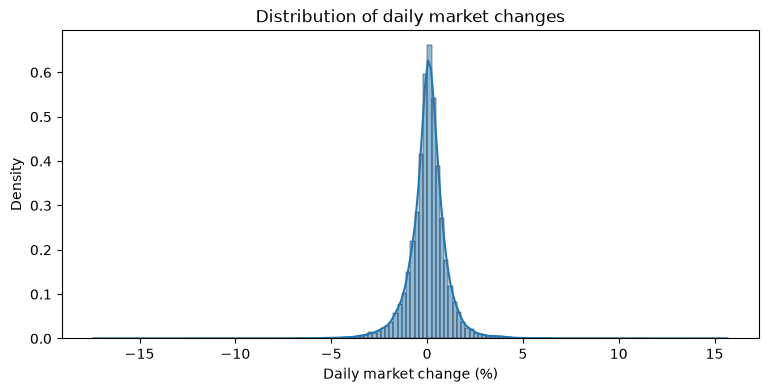

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

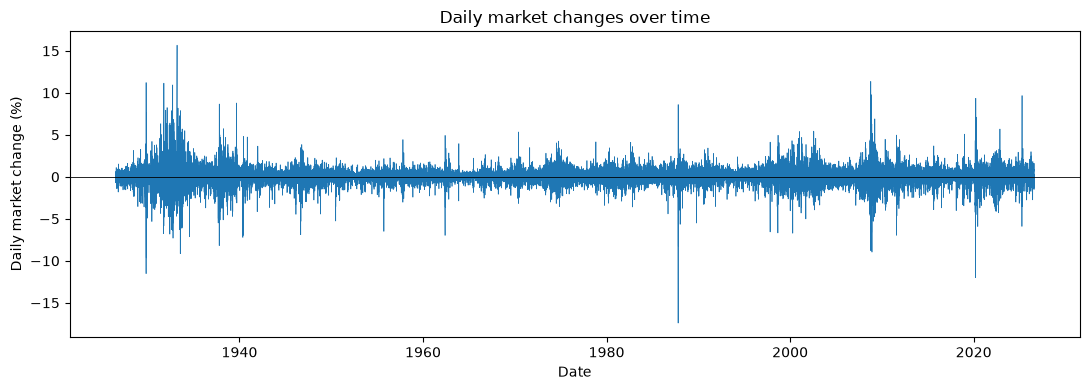

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
# make a categorical column "direction_t" 
direction_categories = ['Down / flat', 'Up']
np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat')

df['direction_t'] = pd.Categorical(
    np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat'),
    categories=direction_categories,
    ordered=True,
)

In [5]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)

In [6]:
df[["direction_t","direction_tp1"]]

,direction_t,direction_tp1
0,Up,Up
1,Up,Up
2,Up,Up
3,Up,Up
4,Up,Down / flat
...,...,...
26291,Up,Up
26292,Up,Down / flat
26293,Down / flat,Up
26294,Up,Up


In [7]:
pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = True, margins = True)

direction_tp1,Down / flat,Up,All
direction_t,,,
Down / flat,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


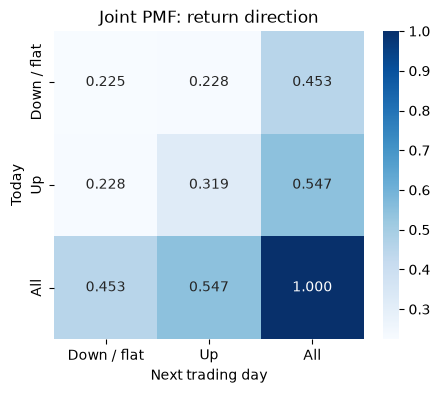

In [8]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = True, margins = True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [9]:
# Plot the conditional PMF
pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = 'index')

direction_tp1,Down / flat,Up
direction_t,,
Down / flat,0.496221,0.503779
Up,0.416974,0.583026


<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions?
    - Up transitions are more common than down transitions. The market is Up on about 54.7% of trading days and Down/flat on about 45.3%, and tomorrow's marginal is nearly the same. Of the four transitions, Up to Up is the most common (about 31.9% of day pairs) and Down/flat to Down/flat is the least common (about 22.5%). The two mixed transitions are each about 22.8%.

- Are you more likely to transition to an Up day from a Down or Up day?
    - You are more like to transition to an Up day. P(Up tomorrow | Up today) = 0.583, but P(Up tomorrow | Down/flat today) = 0.504. 

</div>

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [10]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df['market_return_pct'], bins = [-np.inf, -1, -0.1, 0.1,1, np.inf], labels = return_categories)


In [11]:
df['return_bin'].value_counts()

return_bin
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [12]:
#make y_t and y_tp1 columns for the return bins
df['y_t'] = df['return_bin']
df['y_tp1'] = df['return_bin'].shift(-1)

In [13]:
pd.crosstab(df['y_t'], df['y_tp1'], normalize = True, margins = True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
  - Of the 26,296 trading days, 9,785 fall into small gain (about 37.2%), 7,452 fall into small loss (about 28.3%), 3,441 fall into near zero (about 13.1%), 2,859 fall into large gain (about 10.9%), and 2,759 fall into large loss (about 10.5%).

- Which are the most or least common?
  - Small gain is the most common bin, followed by small loss, while large loss is the least common, just below large gain. Most days are small moves in either direction, and large moves are less common. Gains outnumbers losses in both the small and large categories.
  </div>

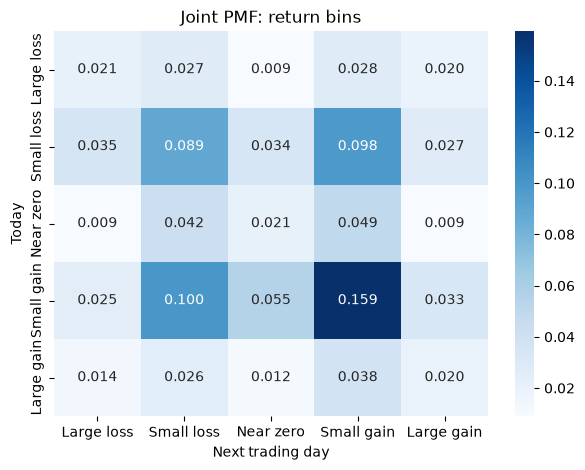

In [14]:
#joint PMF with marginals
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are most likely to occur? 
    - The most likely transition to occur is small gain to small gain, which accounts for about 15.9% of all day pairs. Next are small gain to small loss (about 10.0%) and small loss to small gain (about 9.8%), followed by small loss to small loss (about 8.9%). These are the most likely transitions mainly because small gain and small loss are the two most common states
</div>

In [15]:
#conditional PMF 
pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


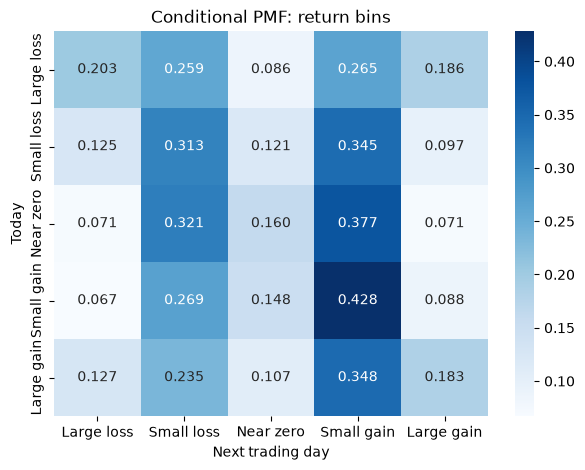

In [16]:
#joint PMF with marginals
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize="index"),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
    - For every current state, the two most likely next states are small gain and small loss. After a large loss, they are small gain and small loss (about 26.5% and 25.9%, respectively). After a small loss, they are small gain and small loss (about 34.5% and 31.3%, respectively). After a near zero day, they are small gain and small loss (about 37.7% and 32.1%, respectively). After a small gain, they are small gain  and small loss (about 42.8% and 26.9%, respectively). After a large gain, they are small gain and small loss (about 34.8% and 23.5%, respectively).

- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
    - The large loss and large gain rows are the closest to uniform, since their probabilities are spread more evenly, but near zero is still noticeably below 0.2 in both. The small gain row is the farthest from uniform, with a peaking at approx. 0.43 on small gain and only about 0.07 on large loss. The near zero and small loss rows are also not uniform, with small gain and small loss far above 0.2. Overall, none of the rows are very close to uniform, mainly because the states are not equally common.

- Is it relatively easy or difficult to predict the next state?
    - It is relatively difficult to predict the next state. The most likely next state is never above about 43% (small gain after a small gain), and in most rows it is only about 35% or less. The rows also look similar to each other, with small gain and small loss on top regardless of today's state, so knowing today's state does not change the forecast very much

</div>

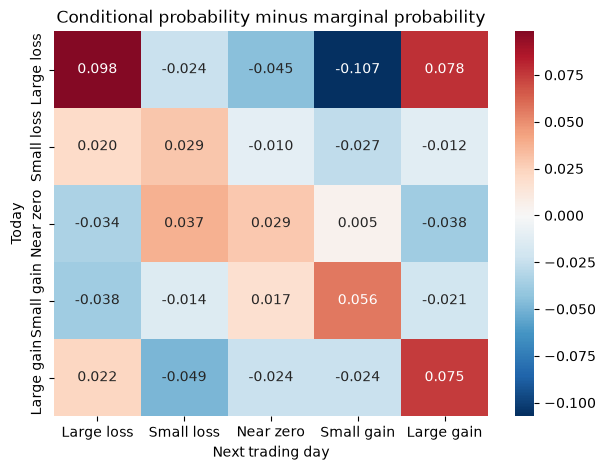

In [17]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = next_state_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True).sum(axis=0)
next_state_pmf

conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize="index")
# subtract it from each row of the conditional PMF and plot as a heatmap
# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(conditional.sub(next_state_pmf, axis='columns'),
            annot=True, fmt='.3f', center=0, cmap='RdBu_r', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today',
       title='Conditional probability minus marginal probability')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?

  - The clearest pattern is on the diagonal where every state is more likely to be followed by itself than independence predicts. The largest excesses are large loss to large loss (about 0.098), large gain to large gain (about 0.075), and small gain to small gain (about 0.056), with smaller excesses for small loss to small loss and near zero to near zero (each about 0.03). Large also tend to follow large of the opposite sign, such as large loss to large gain (about 0.078) and large gain to large loss (about 0.022). Less likely transitions are large loss to small gain (about −0.107), small gain to large loss (about −0.038), large gain to small loss (about −0.049), and near zero to large loss or large gain (about −0.034 and −0.038, respectively)

- Does knowing today's state change the forecast for tomorrow?
  - Yes, somewhat. If today's state were irrelevant, every row would be zero everywhere in the heatmap. Instead, the deviations are as large as 5 to 10 percentage points in some cells. The information is mostly about the size of tomorrow's move (volatility clustering) rather than its sign. After a large move of either sign, a large move tomorrow is more likely, and after a small gain or near zero day, a large move is less likely. The effects are modest compared with the overall probabilities, so the forecast improves only a little.

- How is this comparison different from comparing each row to a uniform PMF with probability .2?
  - The uniform PMF assumes all five states are equally likely, which is not true here, since small gain happens about 37% of the time and large loss only about 10%. A row can therefore look far from uniform even if today's state has no effect at all. Subtracting the marginal PMF of tomorrow's state uses the correct baseline for "no relationship." What is left is the part of each row that is actually due to today's state, rather than to some states simply being more common than others.
</div>

In [18]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t
df.groupby("y_t")["market_return_pct_tp1"].describe()

C:\Users\clair\AppData\Local\Temp\ipykernel_24972\817726577.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("y_t")["market_return_pct_tp1"].describe()


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 
  
  - The expected tomorrow returns are small in every state. After a large loss, the mean is about −0.04%. After a small loss, it is about −0.04%. After a near zero day, it is about 0.02%. After a small gain, it is about 0.11%, and after a large gain it is about 0.16%

- How do the min and max values for tomorrow vary across states? 
  - The extremes vary a lot. The worst next-day return is about −17.4% after a large loss and about −12.0% after a large gain, compared with about −8.2% after near zero and small gain days. The best next-day return is about 15.7% after a large gain, versus about 11.2% after a large loss, about 11.4% after a small loss, and only about 5.5% after a near zero day

- Which states have the highest standard deviation for tomorrow's percent returns? 
    - Large loss has the highest standard deviation (about 1.72), followed by large gain (about 1.38). Small loss is next (about 1.01), and near zero and small gain (both about 0.83) are the lowest.

- Describe any patterns in the volatility you notice.
    - The standard deviation is highest after large moves and lower after small moves, even though the mean returns are all close to zero. It matches the earlier heatmap, where large states were followed by large states more often than independence predicts. The pattern is also asymmetric, a large loss is followed by more volatility (1.72) than a large gain (1.38), and small loss days (1.01) are followed by more volatility than small gain days (0.83). Down days seem to have more uncertainty than up days of the same size

</div>

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [19]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


In [20]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap
quantile_joint = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize=True, margins = False
)

<Axes: xlabel='y_tp1', ylabel='y_t'>

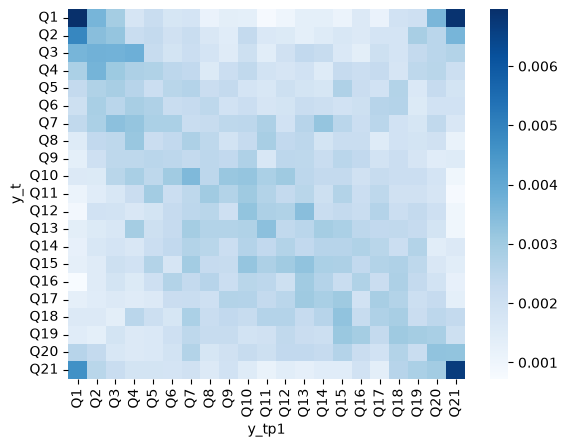

In [21]:
sns.heatmap(quantile_joint, cmap='Blues')

<Axes: xlabel='y_tp1', ylabel='y_t'>

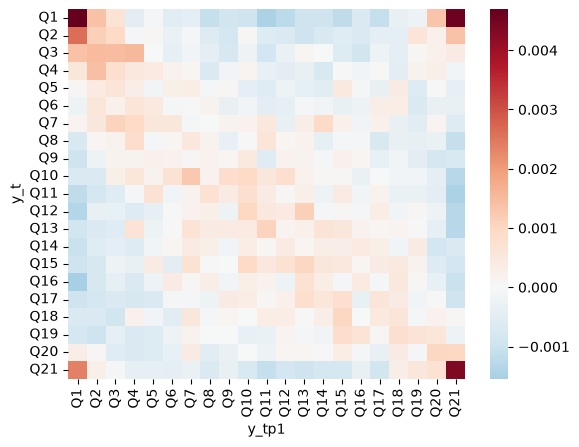

In [22]:
sns.heatmap(quantile_joint - 1/bins**2, cmap='RdBu_r', center=0)

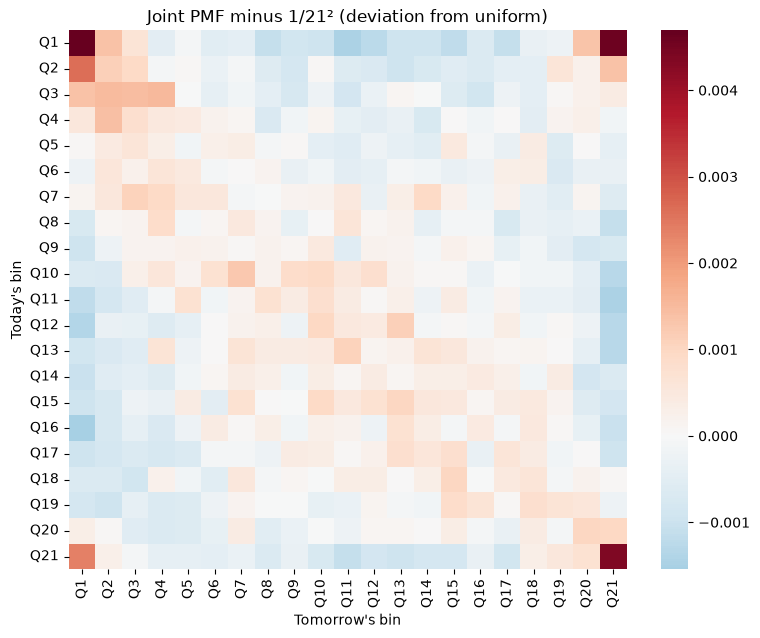

In [23]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(quantile_joint - 1/bins**2, cmap='RdBu_r', center=0, ax=ax)
ax.set_title("Joint PMF minus 1/21² (deviation from uniform)")
ax.set_xlabel("Tomorrow's bin")
ax.set_ylabel("Today's bin")
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Do you see any obvious patterns?

    - Yes. The strongest deviations from uniform are in the corners. Q1 to Q1 and Q21 to Q21 are the darkest cells, so the worst days tend to be followed by other very bad days and the best days by other very good days. The off-diagonal corners are also strong: Q1 to Q21 (top right) is dark red, and Q21 to Q1 (bottom left) is orange. This means extreme days are followed by extreme days of either sign. The upper-left block (Q1 to Q4 followed by Q1 to Q4) is also mildly positive, so losses of different sizes tend to cluster together. The extremes also show up as blue cells in the rest of the extreme rows and columns. A middle-sized return today (roughly Q8 to Q17) is less likely than uniform to be followed by Q21 tomorrow.

</div>

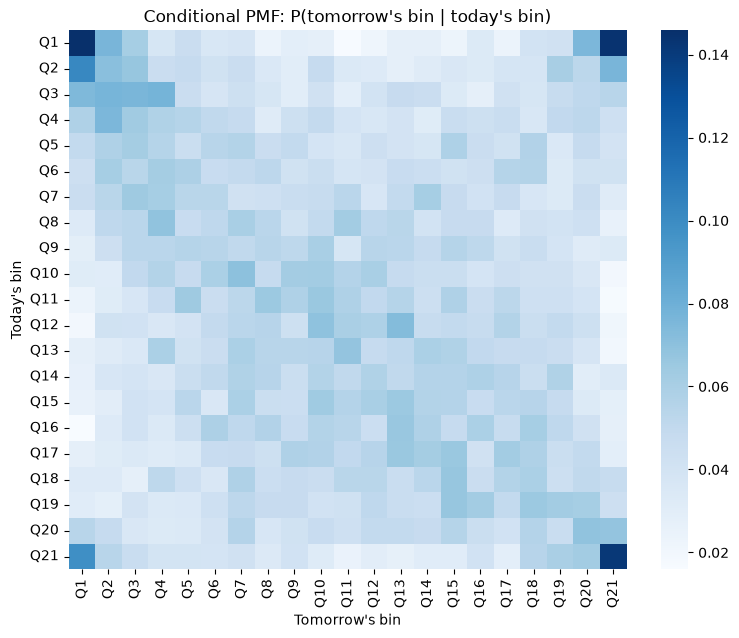

In [24]:
# compute and plot the conditional
quantile_cond = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(quantile_cond, cmap='Blues', ax=ax)
ax.set_title("Conditional PMF: P(tomorrow's bin | today's bin)")
ax.set_xlabel("Tomorrow's bin")
ax.set_ylabel("Today's bin")
plt.show()

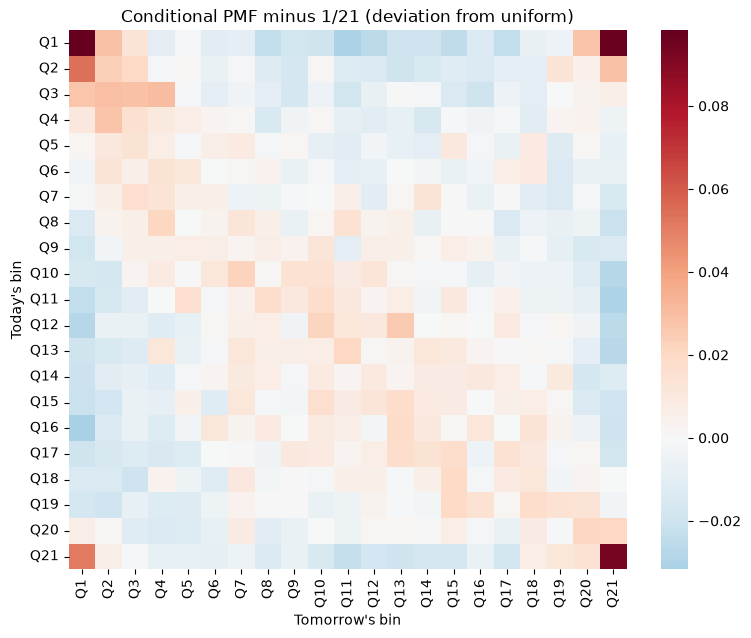

In [25]:
# Subtract 1/21 from the PMF before plotting it, to normalize away the uniform PMF,
# and see systematic deviations from uniformly random transitions.
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(quantile_cond - 1/bins, cmap='RdBu_r', center=0, ax=ax)
ax.set_title("Conditional PMF minus 1/21 (deviation from uniform)")
ax.set_xlabel("Tomorrow's bin")
ax.set_ylabel("Today's bin")
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Do you see any obvious patterns?
    - Yes. The strongest deviations are in the corners. After the worst days (Q1) or the best days (Q21), tomorrow is much more likely to be another extreme day, in either direction. Q1 to Q1, Q1 to Q21, and Q21 to Q21 are all about 0.10 above uniform. After moderate days (around Q10 to Q13), extreme days tomorrow are less likely than uniform. Today's size predicts tomorrow's size much better than it predicts tomorrow's direction.

</div>

In [26]:
# compute the next day's min, mean, and max conditional on each bin
next_day_stats = (
    df.groupby('y_t', observed=True)['market_return_pct_tp1']
      .agg(['min', 'mean', 'max'])
)
next_day_stats

,min,mean,max
y_t,,,
Q1,-17.41,-0.013713,11.22
Q2,-7.36,-0.076712,6.36
Q3,-8.79,-0.097084,11.36
Q4,-8.28,-0.058594,6.16
Q5,-6.89,-0.024211,4.56
Q6,-11.23,-0.022692,6.37
Q7,-3.94,-0.030241,7.37
Q8,-3.40,-0.014303,4.76
Q9,-6.00,0.025860,5.49


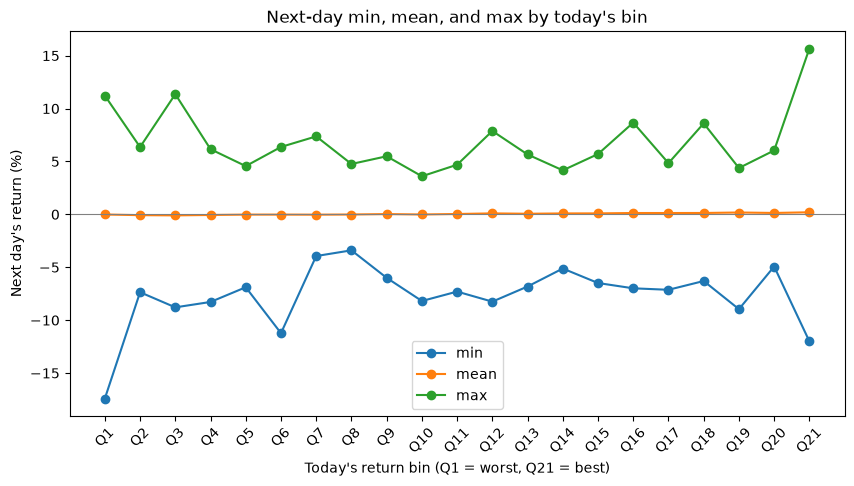

In [27]:
#plot as lines on a graph against the bins
fig, ax = plt.subplots(figsize=(10, 5))
next_day_stats.plot(ax=ax, marker='o')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_xlabel("Today's return bin (Q1 = worst, Q21 = best)")
ax.set_ylabel("Next day's return (%)")
ax.set_title("Next-day min, mean, and max by today's bin")
ax.set_xticks(range(len(next_day_stats)))
ax.set_xticklabels(next_day_stats.index, rotation=45)
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Do you see any obvious patterns?
    - Yes. The mean next-day return is close to zero for every bin, but it trends upward from about -0.1% after the lower bins (Q2 to Q4) to about 0.2% after Q21, so higher returns today are followed by slightly higher returns tomorrow. The min and max are much larger in magnitude than the mean and are widest at the extremes. After Q1, the worst next-day return is about -17.4% and the best is approx. 11.2%, and after Q21 they are about -12.0% and 15.7%. The middle bins have narrower ranges

</div>

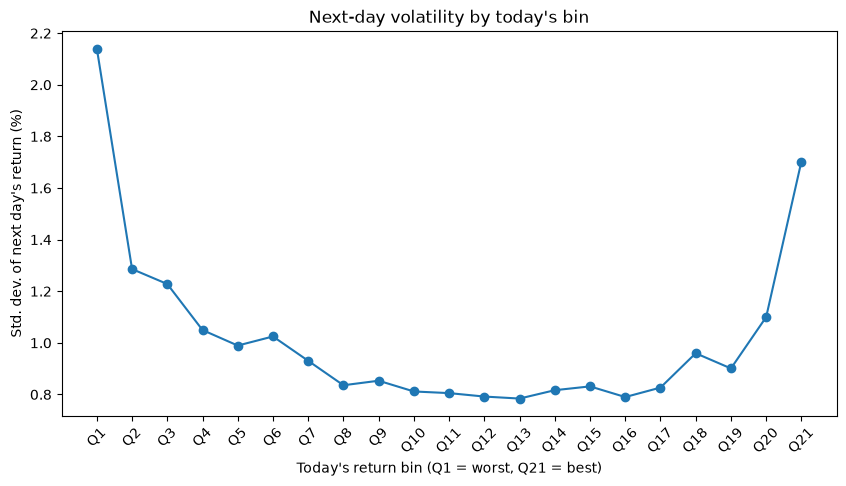

In [28]:
#compute the next day's standard deviation, and plot it as a line graph against the bins. 
next_day_std = df.groupby('y_t', observed=True)['market_return_pct_tp1'].std()

fig, ax = plt.subplots(figsize=(10, 5))
next_day_std.plot(ax=ax, marker='o')
ax.set_xlabel("Today's return bin (Q1 = worst, Q21 = best)")
ax.set_ylabel("Std. dev. of next day's return (%)")
ax.set_title("Next-day volatility by today's bin")
ax.set_xticks(range(len(next_day_std)))
ax.set_xticklabels(next_day_std.index, rotation=45)
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Do you see any obvious patterns?
    - Yes, there are patterns. The standard deviation of next-day returns is U-shaped across today's bins. It is highest after the most extreme days, at approx. 2.1% after Q1 and about 1.7% after Q21. It is lowest after moderate days, at about 0.8% for bins around Q8 to Q17. The left side is higher and steeper than the right, so very bad days are followed by more volatility than very good days of the same rank. This is expected because big moves today, in either direction, predict a wider range of outcomes tomorrow, which matches the min/max plot and the corner pattern in the heatmaps

</div>

<div class='alert alert-info'><b>Answer the following:</b>

- How easy is it to predict the market?
    - It is difficult to predict the direction of the market. The expected next-day return is within about ±0.2% of zero for every bin, and the actual next-day returns range from about −17% to 16%, so today's return tells us almost nothing about whether tomorrow will be up or down. The conditional PMF rows are also fairly close to uniform apart from the corners. Today's return does predict the size of tomorrow's move, the standard deviation is about 2 to 3 times higher after extreme days (about 1.7% to 2.1%) than after moderate days (about 0.8%). So we can say something about how risky tomorrow will be, but not about which way the market will go.

</div>